# Locating the DBTT with active learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/digiLab-ai/ukaea-dbtt-active-learning/blob/main/DBTT_active_learning.ipynb)

A Charpy impact campaign exists to answer one question: **where is the
ductile–brittle transition temperature, and how sure are we?** Specimens are
expensive, so the campaign should spend them where they tell us most.

This notebook does the whole thing end to end, against a live
[Uncertainty Engine](https://uncertaintyengine.ai) project:

| Section | What it does |
| --- | --- |
| [1. A simulated test campaign](#scrollTo=section-1) | A Charpy simulator stands in for the test house, so every estimate can be scored against a known truth |
| [2. Active learning on the Engine](#scrollTo=section-2) | Five workflows — train, recommend, visualise, predict, validate — saved to the project and driven in a loop |
| [3. The DBTT, with its uncertainty](#scrollTo=section-3) | The transition read off the trained model, with the uncertainty that comes with it |

Energy absorbed is modelled as an asymmetric hyperbolic tangent (AHT):

$$Y(T) = \frac{LS + US}{2} + \frac{US - LS}{2}\,\tanh\!\left(\frac{T - \mathrm{DBTT}}{C(T)}\right)$$

with $C(T) = C_\mathrm{lower}$ below the DBTT and $C_\mathrm{upper}$ above it, and
heteroscedastic measurement noise $\sigma(T) = \sigma_\mathrm{base} + \sigma_\mathrm{rel}\,Y(T)$.

> **Everything you might want to change is in [Settings](#scrollTo=settings),**
> the first cell below — the material, the noise, the initial design, the
> kernel, the acquisition and the plot colours. Nothing further down needs
> editing to re-run on a different material or a different campaign.

> **The code lives in collapsed cells.** Each one is titled with what it
> covers; click the title to unfold it. Nothing is imported from this
> repository, so the notebook runs anywhere its dependencies do.

---
## Setup

The only thing not already on a Colab runtime is the Uncertainty Engine SDK.
`uncertainty-engine` on PyPI is the **remote API client**; an unpublished
distribution of the same name provides an in-process modelling library and
shadows it, so if imports start failing in confusing ways, check which one the
environment has.

In [1]:
import importlib.util
import sys

IN_COLAB = "google.colab" in sys.modules

missing = [
    spec
    for module, spec in [
        ("uncertainty_engine", "uncertainty-engine>=0.15,<0.16"),
        ("dotenv", "python-dotenv>=1.0"),
        ("pydantic", "pydantic>=2.6"),
    ]
    if importlib.util.find_spec(module) is None
]

if missing:
    %pip install --quiet {" ".join(missing)}
    print("installed:", ", ".join(missing))
else:
    print("nothing to install")

nothing to install


In [2]:
import io
import os
import tempfile
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Dict, List, Optional, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pydantic import BaseModel, ConfigDict, Field, model_validator

from importlib.metadata import version

print(f"uncertainty-engine SDK {version('uncertainty-engine')}")

uncertainty-engine SDK 0.15.0


---
<a id="settings"></a>
## Settings

Everything meant to be changed lives in the next cell. Nothing below it needs
editing to re-run this notebook on a different material, a different campaign
or a different model.

The first two groups describe the **specimen the simulator breaks** — in a real
campaign they are the unknown the testing exists to find, and here they are
the ground truth every estimate is scored against. The rest configure the
campaign, the Engine model, and the figures.

In [ ]:
# ====================== THE MATERIAL (ground truth) ======================
# A real campaign does not know these. The simulator does, so the notebook
# can score itself. Y(T) = (LS+US)/2 + (US-LS)/2 * tanh((T - DBTT) / C(T))
TRUE_DBTT        = -40.0    # C   the transition temperature to be found
TRUE_LOWER_SHELF =   5.0    # J   brittle plateau, LS
TRUE_UPPER_SHELF = 200.0    # J   ductile plateau, US
TRUE_WIDTH_LOWER =  30.0    # C   transition width C below the DBTT
TRUE_WIDTH_UPPER =  30.0    # C   ... and above it; equal values = symmetric

# ===================== MEASUREMENT NOISE =================================
# sigma(T) = NOISE_BASE + NOISE_RELATIVE * Y(T): Charpy scatter grows with
# absorbed energy, so the ductile shelf is noisier than the brittle one.
NOISE_BASE     = 3.0        # J   scatter floor, present even on the lower shelf
NOISE_RELATIVE = 0.10       # -   added scatter as a fraction of energy absorbed
SIMULATOR_SEED = 0          # reproducible specimens; None for a fresh campaign

# ===================== THE CAMPAIGN ======================================
BOUNDS               = (-120.0, 100.0)              # testable range [C]
SEED_TEMPERATURES    = [-120.0, 100.0] # the initial design
ITERATIONS           = 6                            # active-learning iterations
POINTS_PER_ITERATION = 1                            # specimens chosen per iteration

# ===================== THE MODEL =========================================
# Straight through to the Engine's ModelConfig and Recommend nodes.
KERNEL      = "M32"                # LIN M12 M32 M52 PER RBF RQF, composed
                                   # with + (additive) and * (multiplicative),
                                   # e.g. "(M52*PER)+RQF". LIN+RBF = a linear
                                   # trend plus smooth local structure.
MODEL_TYPE  = "SingleTaskGPTorch"  # or SingleTaskVariationalGPTorch
WARP_INPUTS = False                # learn a transformation of the input space;
                                   # worth trying where the curve varies at
                                   # different rates across the range
MODEL_SEED  = 0

ACQUISITION = "qNIPV"              # see ACQUISITIONS in section 2 for the rest

# The GP's MEAN FUNCTION is deliberately absent from this list: the Engine
# does not expose it. `ModelConfig` takes a kernel, not a mean, and
# `TrainModel` takes only (config, inputs, outputs). The kernel is the lever
# you have — the LIN term in "LIN+RBF" is what lets the fit carry a linear
# trend, which is most of what a non-constant mean would buy you here.

# ===================== PLOT COLOURS ======================================
COLOURS = {
    "truth":      "0.4",   # the true transition curve
    "gp":         "C0",    # GP mean and band, in the per-iteration panels
    "posterior":  "C3",    # the final GP posterior, section 3
    "tests":      "C1",    # specimens measured
    "picked":     "C3",    # where the acquisition chose to test next
    "dbtt":       "C3",    # the DBTT estimated from the model
    "true_dbtt":  "C2",    # the DBTT the simulator actually used
}

### Credentials

Three values are needed to reach the Engine:

| Key | What it is |
| --- | --- |
| `UE_USERNAME` | your Uncertainty Engine login |
| `UE_PASSWORD` | your password |
| `UE_PROJECT_NAME` | the project to work in. It **must already exist** — projects can be viewed and added to here: [https://uncertaintyengine.ai/projects](https://uncertaintyengine.ai/projects) |

**In VS Code, or any local Jupyter.** Put them in a file called `.env`, beside
this notebook:

```
UE_USERNAME=you@example.com
UE_PASSWORD=your-password
UE_PROJECT_NAME=Test
```

`.env` is listed in `.gitignore` and must never be committed. Copy
`.env.example` rather than editing it, so the template stays in the repository
with its keys blank. In VS Code, pick the kernel from the virtualenv you
installed into — the top-right kernel picker — and `python-dotenv` will read
the file from the notebook's working directory.

**In Google Colab.** Do not upload a `.env`: a runtime's filesystem outlives
the cell that wrote it and is easy to leak into a saved notebook. Use the
Secrets panel instead — the **🔑 key icon** in the left sidebar — adding one
secret per key above and switching **Notebook access** on for each. The Colab
badge at the top of this notebook opens it straight from GitHub; because the
repository is internal you will be asked to authorise Colab's GitHub access the
first time.

`load_credentials()` tries Colab secrets first, then `.env`, then whatever is
already in the environment. It returns only *where* the credentials came from,
never what they are, so this cell's output is safe to commit.

In [4]:
#@title Credentials and connection { display-mode: "form" }
# Covers
#   load_credentials()   Colab secrets first, then `.env`, then the environment.
#                        Returns only *where* they came from, never the values.
#   project_name()       the Engine project to work in, from $UE_PROJECT_NAME.
#   connect()            authenticate and resolve (client, project_id).
#
# Projects are created in the Uncertainty Engine GUI, not from the SDK, so the
# project named here must already exist.

CREDENTIAL_KEYS = ("UE_USERNAME", "UE_PASSWORD")
PROJECT_KEY = "UE_PROJECT_NAME"


def load_credentials(env_path: str = ".env") -> str:
    """Load Engine credentials into the process environment.

    Returns ``"colab"``, ``"dotenv"``, ``"environment"`` or ``"missing"``. The
    values themselves are never returned or logged, so the output of this cell
    is safe to commit with the notebook.
    """
    keys = CREDENTIAL_KEYS + (PROJECT_KEY,)

    try:  # Google Colab secrets (the key icon in the left sidebar)
        from google.colab import userdata  # type: ignore

        found = False
        for key in keys:
            try:
                os.environ[key] = userdata.get(key)
                found = True
            except Exception:
                pass
        if found:
            return "colab"
    except ImportError:
        pass

    path = Path(env_path)
    if path.exists():
        from dotenv import load_dotenv

        load_dotenv(path)
        return "dotenv"

    if all(os.environ.get(key) for key in CREDENTIAL_KEYS):
        return "environment"
    return "missing"


def credentials_present() -> bool:
    """Whether every credential key is set. Does not read the values."""
    return all(os.environ.get(key) for key in CREDENTIAL_KEYS)


def project_name(override: Optional[str] = None) -> str:
    """The Engine project to work in: ``override``, else ``$UE_PROJECT_NAME``."""
    name = override or os.environ.get(PROJECT_KEY)
    if not name:
        raise RuntimeError(
            f"No Engine project named. Set {PROJECT_KEY} in your .env (or in "
            "Colab secrets), or pass project_name=... explicitly. Projects are "
            "created in the Uncertainty Engine GUI, not from the SDK."
        )
    return name


def connect(name: Optional[str] = None):
    """Authenticate and resolve a project id. Returns ``(client, project_id)``."""
    from uncertainty_engine import Client

    if not credentials_present():
        raise RuntimeError(
            "Uncertainty Engine credentials are not set. Put "
            f"{' and '.join(CREDENTIAL_KEYS)} in a .env file beside this "
            "notebook, or in Colab secrets, then re-run load_credentials()."
        )

    client = Client()
    client.authenticate()
    return client, client.projects.get_project_id_by_name(project_name(name))

In [5]:
source = load_credentials()
print(f"credentials from: {source}")

client, project_id = connect()
print(f"project {project_name()!r} -> {project_id}")

credentials from: dotenv
project 'Test' -> 6ae27221bac4a9e13468f79d


---
<a id="section-1"></a>
## 1. A simulated test campaign

The simulator stands in for the test house. It follows the uncertainty-engine
`Simulator` contract — config-driven construction, a leaf `_forward(X)` holding
the raw $X \to y$ map, and the public verb `simulate(X)` returning a
`SimulationResult` — so code written against it ports to the real thing with a
change of import.

Because it is a simulator it knows the answer, and that is the point: every
estimate later in the notebook can be scored against a DBTT we actually know.

In [6]:
#@title The Charpy simulator { display-mode: "form" }
# Covers
#   AHTParams / NoiseParams / SpecimenParams / CharpySimulatorConfig
#                        validated pydantic config; a whole campaign is
#                        reproducible from these fields alone.
#   SimulationResult     what `simulate` returns: `y` plus auxiliary payload.
#   Simulator            the uncertainty-engine `Simulator` noun, in miniature:
#                        config-driven construction, a leaf `_forward(X)`
#                        implementing the raw X -> y map, and the public verb
#                        `simulate(X)`. Code written against it ports to the
#                        engine with a change of import.
#   CharpySimulator      test temperature [C] -> energy absorbed [J], as an
#                        asymmetric hyperbolic tangent plus heteroscedastic
#                        noise. `run()` returns test-house-shaped rows.
#   plot_dataset         scatter of energy absorbed against test temperature.
#
# The forward map is *stochastic*: one `simulate` call is one broken specimen,
# a single realisation rather than a summary of the output law.

#: Column headers of the test-result table, matching the test-house spreadsheet.
COLUMNS = [
    "Material", "Condition", "Processing", "Orientation",
    "NEURONE specimen ID", "Test house specimen ID", "Specimen Design",
    "Specimen location", "Specimen Type", "Notch type",
    "Test temperature (C)", "Energy absorbed (J)",
]

TEMPERATURE_COL = "Test temperature (C)"
ENERGY_COL = "Energy absorbed (J)"


class SimulationResult(BaseModel):
    """`y` is the canonical output of the forward map; `outputs` is everything else."""

    model_config = ConfigDict(arbitrary_types_allowed=True)

    y: Any = Field(None, description="Canonical output(s) of the forward map X -> y.")
    outputs: Dict[str, Any] = Field(
        default_factory=dict,
        description="Auxiliary payload: diagnostics, provenance, units, ground truth.",
    )


class AHTParams(BaseModel):
    """Asymmetric hyperbolic tangent (AHT) transition curve.

        Y(T) = (LS + US) / 2 + (US - LS) / 2 * tanh((T - DBTT) / C(T))

    with ``C(T) = width_lower`` below the DBTT and ``width_upper`` above it.
    Setting the two widths equal recovers the symmetric hyperbolic tangent.
    """

    model_config = ConfigDict(extra="forbid")

    lower_shelf: float = Field(5.0, ge=0.0, description="Lower (brittle) shelf energy, LS [J].")
    upper_shelf: float = Field(200.0, gt=0.0, description="Upper (ductile) shelf energy, US [J].")
    dbtt: float = Field(-40.0, description="Ductile-brittle transition temperature [C].")
    width_lower: float = Field(30.0, gt=0.0, description="Transition width C below the DBTT [C].")
    width_upper: float = Field(30.0, gt=0.0, description="Transition width C above the DBTT [C].")

    @model_validator(mode="after")
    def _check_shelves(self) -> "AHTParams":
        if self.upper_shelf <= self.lower_shelf:
            raise ValueError("upper_shelf must be greater than lower_shelf")
        return self


class NoiseParams(BaseModel):
    """Heteroscedastic measurement noise, ``sigma(T) = base + relative * Y(T)``."""

    model_config = ConfigDict(extra="forbid")

    base: float = Field(3.0, ge=0.0, description="Constant noise standard deviation [J].")
    relative: float = Field(0.10, ge=0.0, description="Noise std as a fraction of true energy [-].")
    energy_floor: float = Field(
        0.0, ge=0.0,
        description="Sampled energies clipped here [J]; a Charpy test cannot absorb negative energy.",
    )


class SpecimenParams(BaseModel):
    """Specimen provenance carried through to the test-result table."""

    model_config = ConfigDict(extra="forbid")

    material: str = Field("EUROFER EAF", description="Material designation.")
    condition: str = Field("Base", description="Material condition.")
    processing: str = Field("Rolled", description="Processing route.")
    orientation: str = Field("RD", description="Specimen orientation.")
    specimen_design: str = Field("ASTM", description="Specimen design standard.")
    specimen_location: str = Field("EAF 1a Plate 1", description="Where the specimen came from.")
    specimen_type: str = Field("Charpy", description="Test specimen type.")
    notch_type: str = Field("V notch", description="Notch geometry.")
    neurone_id_prefix: str = Field("NRN2025-", description="Prefix for generated NEURONE IDs.")
    neurone_id_digits: int = Field(4, ge=1, description="Zero-padded width of the NEURONE ID.")


class CharpySimulatorConfig(BaseModel):
    """Everything `CharpySimulator` needs, as validated fields."""

    model_config = ConfigDict(extra="forbid")

    name: str = Field("eurofer_eaf", description="Short name for this campaign.")
    description: Optional[str] = Field(None, description="Free-text note.")
    curve: AHTParams = Field(default_factory=AHTParams)
    noise: NoiseParams = Field(default_factory=NoiseParams)
    specimen: SpecimenParams = Field(default_factory=SpecimenParams)
    seed: Optional[int] = Field(0, description="Random seed. None gives non-reproducible draws.")
    temperature_range: tuple = Field(
        (-150.0, 100.0),
        description="Physically sensible test-temperature bounds [C]; requests outside are rejected.",
    )

    @model_validator(mode="after")
    def _check_range(self) -> "CharpySimulatorConfig":
        lo, hi = self.temperature_range
        if hi <= lo:
            raise ValueError("temperature_range must be (low, high) with high > low")
        return self


class Simulator:
    """Abstract base for all simulators: the ``X -> y`` forward map.

    Construction is config-driven; ``X`` is an argument to ``simulate``, never
    stored on the config.
    """

    def __init__(self, config) -> None:
        self.config = config

    def _forward(self, X):
        """Evaluate the raw forward map ``X -> y``. Leaves implement this."""
        raise NotImplementedError

    def simulate(self, X) -> SimulationResult:
        """One evaluation of the forward map, wrapped in a result."""
        return self.build_result(X, self._forward(X))

    def build_result(self, X, y) -> SimulationResult:
        """The extension point every ``simulate`` goes through."""
        return SimulationResult(y=y)

    @classmethod
    def describe(cls) -> Dict[str, Any]:
        """Introspect the leaf without instantiating it."""
        return {
            "name": cls.__name__,
            "summary": (cls.__doc__ or "").strip().split("\n")[0],
        }


class CharpySimulator(Simulator):
    """Charpy impact test: test temperature [C] -> energy absorbed [J].

    Repeated calls at the same temperature give different energies, as in a
    real campaign.
    """

    def __init__(self, config: Optional[CharpySimulatorConfig] = None) -> None:
        super().__init__(config or CharpySimulatorConfig())
        self._rng = np.random.default_rng(self.config.seed)

    # ----- the forward map -----
    def _forward(self, X) -> np.ndarray:
        """Draw noisy energy-absorbed measurements [J]. Advances the random state."""
        t = np.atleast_1d(np.asarray(X, dtype=float))
        self._validate_temperatures(t)
        draw = self._rng.normal(loc=self.true_curve(t), scale=self.noise_std(t))
        return np.clip(draw, self.config.noise.energy_floor, None)

    def build_result(self, X, y) -> SimulationResult:
        """Wrap the measurement, carrying the ground truth as auxiliary payload.

        ``outputs["true_energy"]`` and ``outputs["noise_std"]`` have **no
        counterpart in a real experiment**. They are here to score how well the
        active learning recovers the truth, and must never be fed to the GP.
        """
        t = np.atleast_1d(np.asarray(X, dtype=float))
        return SimulationResult(
            y=y,
            outputs={
                "temperature": t,
                "true_energy": self.true_curve(t),
                "noise_std": self.noise_std(t),
                "dbtt": self.dbtt,
                "units": {"temperature": "C", "energy": "J"},
            },
        )

    # ----- ground truth (simulator-only) -----
    def true_curve(self, temperature) -> np.ndarray:
        """Noise-free energy absorbed [J] at the given temperature(s) [C]."""
        curve = self.config.curve
        t = np.asarray(temperature, dtype=float)
        width = np.where(t < curve.dbtt, curve.width_lower, curve.width_upper)
        midpoint = 0.5 * (curve.lower_shelf + curve.upper_shelf)
        amplitude = 0.5 * (curve.upper_shelf - curve.lower_shelf)
        return midpoint + amplitude * np.tanh((t - curve.dbtt) / width)

    def noise_std(self, temperature) -> np.ndarray:
        """Measurement standard deviation [J] at the given temperature(s) [C]."""
        noise = self.config.noise
        return noise.base + noise.relative * self.true_curve(temperature)

    @property
    def dbtt(self) -> float:
        """The ground-truth DBTT [C] the active-learning loop is chasing."""
        return self.config.curve.dbtt

    # ----- test-campaign convenience -----
    def run(self, temperatures, start_index: int = 1) -> pd.DataFrame:
        """Test specimens at ``temperatures`` and return a test-result table.

        The table carries only what a real test house would report: the
        noise-free truth stays on the `SimulationResult` and never reaches the
        dataset. ``start_index`` continues the specimen numbering.
        """
        result = self.simulate(temperatures)
        t = result.outputs["temperature"]
        spec = self.config.specimen
        numbers = np.arange(start_index, start_index + t.size)

        return pd.DataFrame(
            {
                "Material": spec.material,
                "Condition": spec.condition,
                "Processing": spec.processing,
                "Orientation": spec.orientation,
                "NEURONE specimen ID": [
                    f"{spec.neurone_id_prefix}{n:0{spec.neurone_id_digits}d}" for n in numbers
                ],
                "Test house specimen ID": numbers,
                "Specimen Design": spec.specimen_design,
                "Specimen location": spec.specimen_location,
                "Specimen Type": spec.specimen_type,
                "Notch type": spec.notch_type,
                TEMPERATURE_COL: t,
                ENERGY_COL: np.round(result.y, 2),
            },
            columns=COLUMNS,
        )

    def _validate_temperatures(self, t: np.ndarray) -> None:
        lo, hi = self.config.temperature_range
        if np.any(t < lo) or np.any(t > hi):
            bad = t[(t < lo) | (t > hi)]
            raise ValueError(
                f"Test temperature(s) {bad.tolist()} outside the configured range [{lo}, {hi}] C."
            )


def plot_dataset(data: pd.DataFrame, ax=None, label: str = "Measurements", **scatter_kwargs):
    """Scatter energy absorbed against test temperature."""
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 4.5))

    style = {"s": 45, "color": "k", "zorder": 3}
    style.update(scatter_kwargs)
    ax.scatter(data[TEMPERATURE_COL], data[ENERGY_COL], label=label, **style)

    ax.set_xlabel("Test temperature [C]")
    ax.set_ylabel("Energy absorbed [J]")
    ax.set_title("Charpy impact energy vs temperature")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", fontsize=9)
    return ax

In [7]:
simulator = CharpySimulator(
    CharpySimulatorConfig(
        curve=AHTParams(
            dbtt=TRUE_DBTT,
            lower_shelf=TRUE_LOWER_SHELF, upper_shelf=TRUE_UPPER_SHELF,
            width_lower=TRUE_WIDTH_LOWER, width_upper=TRUE_WIDTH_UPPER,
        ),
        noise=NoiseParams(base=NOISE_BASE, relative=NOISE_RELATIVE),
        seed=SIMULATOR_SEED,
    )
)

print(CharpySimulator.describe())
print(f"\ntrue DBTT: {simulator.dbtt} C")
simulator.config.curve

{'name': 'CharpySimulator', 'summary': 'Charpy impact test: test temperature [C] -> energy absorbed [J].'}

true DBTT: -40.0 C


AHTParams(lower_shelf=5.0, upper_shelf=200.0, dbtt=-40.0, width_lower=30.0, width_upper=30.0)

### One measurement

`simulate(X)` runs the forward map **once**. The map is stochastic, so one call
is one broken specimen — a single realisation, not a summary of the output law.

In [8]:
result = simulator.simulate(-45.0)

print(f"Measured:         {result.y[0]:7.2f} J")
print(f"True (noiseless): {result.outputs['true_energy'][0]:7.2f} J")
print(f"Noise sigma:      {result.outputs['noise_std'][0]:7.2f} J")

Measured:           87.86 J
True (noiseless):   86.40 J
Noise sigma:        11.64 J


`result.outputs` carries the simulator's ground truth alongside the
measurement. This has **no counterpart in a real experiment** — it is here to
score the active learning, and must never reach the GP. Call it again at the
same temperature and you get a different specimen:

In [9]:
repeats = [simulator.simulate(-45.0).y[0] for _ in range(5)]
print("Five specimens at -45 C:", [f"{e:.1f}" for e in repeats])

Five specimens at -45 C: ['84.9', '93.9', '87.6', '80.2', '90.6']


### The initial design

Four specimens, two at each end of the testable range. They pin the shelves
that the transition sits between; without them the curve is unidentifiable, and
the acquisition has nothing to reduce uncertainty *against*. Everything after
this is chosen by the Engine.

In [10]:
campaign = simulator.run(SEED_TEMPERATURES, start_index=1)
campaign[["NEURONE specimen ID", TEMPERATURE_COL, ENERGY_COL]]

,NEURONE specimen ID,Test temperature (C),Energy absorbed (J)
0,NRN2025-0001,-120.0,10.62
1,NRN2025-0002,100.0,221.76


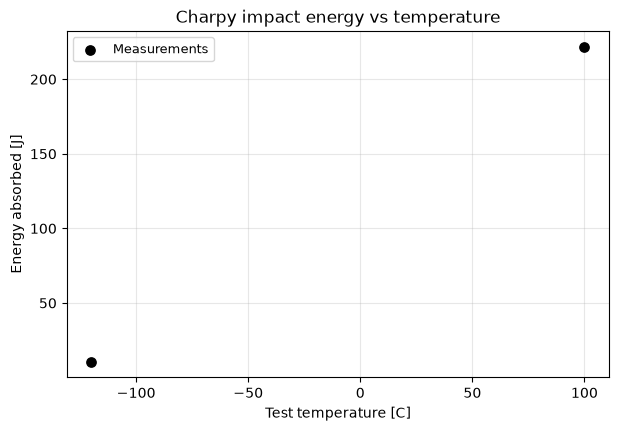

In [11]:
plot_dataset(campaign)
plt.show()

---
<a id="section-2"></a>
## 2. Active learning on the Engine

Everything that models — the GP, the acquisition, the scoring — runs on the
**remote Uncertainty Engine**, not in this process. The cell below assembles
five workflow graphs and saves them to the project, after which they are
visible in the Engine GUI and can be inspected, re-run and edited there. That
is the point of building them programmatically rather than only executing them.

| Workflow | Nodes | Purpose |
| --- | --- | --- |
| **Train model** | `LoadDataset` → `FilterDataset` ×2 → `ModelConfig` → `TrainModel` → `Save` | Fit a GP to the campaign so far |
| **Active Learning** | `LoadModel` → `Recommend` → `Save` | Where to test next |
| **GP plot** | `LoadModel` + `CreateDatasetSlice` → `PredictModel` → `UncertaintyPlot` | The posterior, returned inline with the job |
| **Predict slice** | `LoadModel` + `CreateDatasetSlice` → `PredictModel` → `Save` ×2 | The same posterior, **saved** as project datasets |
| **Validate** | `LoadModel` + `LoadDataset` → `FilterDataset` ×2 → `PredictModel` → `ScoreModel` + `ParityPlot` | Scores and a parity plot |

The campaign is uploaded as **one** dataset and `FilterDataset` splits out the
input and output columns, so each iteration re-uploads a single CSV.

In [12]:
#@title Engine workflow builders { display-mode: "form" }
# Covers, in three groups.
#
# Datasets
#   resource_id()        a project resource's id by name, or None.
#   upload_dataset()     write a frame to the project; *create* on the first
#                        call, *new version of the same id* after that. The
#                        saved workflows point at that id, so it must not move.
#   download_dataset()   a dataset resource back as a frame.
#
# Graph builders — the five workflows, matching the ones exported from the GUI
#   build_training_workflow()        LoadDataset -> FilterDataset x2 ->
#                                    ModelConfig -> TrainModel -> Save
#   build_recommendation_workflow()  LoadModel -> Recommend -> Save
#   build_gp_plot_workflow()         LoadModel + CreateDatasetSlice ->
#                                    PredictModel -> UncertaintyPlot
#   build_prediction_workflow()      the same posterior, but *saved* as two
#                                    project datasets rather than a plot payload
#   build_validation_workflow()      ... -> ScoreModel + ParityPlot
#
# Running and reading
#   save_workflow()      put a graph in the project workspace, by name. It then
#                        shows up in the GUI and can be re-run and edited there.
#   run_saved()          run one by id, optionally overriding node inputs.
#   outputs()            unwrap `JobInfo.outputs`, which nests the map one deep.
#   uncertainty_curve()  the posterior a GP-plot job returns inline.
#   saved_prediction()   the posterior a prediction job saved, downloaded.
#   recommended_points() the points a recommendation job chose.
#
# Node schemas are resolved from the Node Registry at run time (SDK >= 0.15),
# so these follow whatever version the Engine currently serves.

#: Our acquisition names mapped onto the SDK's `AvailableAcquisitions`.
ACQUISITIONS: Dict[str, str] = {
    # Uncertainty reduction - what a characterisation campaign wants.
    "qNIPV": "MonteCarloNegativeIntegratedPosteriorVariance",
    "PSD": "PosteriorStandardDeviation",
    # Optimisation - these chase the *largest* energy, not the transition,
    # so they are the wrong tool here and are listed for completeness.
    "EI": "ExpectedImprovement",
    "LogEI": "LogExpectedImprovement",
    "qEI": "MonteCarloExpectedImprovement",
    "qLogEI": "MonteCarloLogExpectedImprovement",
    "PM": "PosteriorMean",
}

#: The campaign columns the GP is trained on.
INPUT_COLUMNS: List[str] = [TEMPERATURE_COL]
OUTPUT_COLUMNS: List[str] = [ENERGY_COL]


# ----- datasets -------------------------------------------------------------
def resource_id(client, project_id: str, name: str, resource_type: str = "dataset"):
    """The id of a project resource by name, or ``None`` if there is no such one."""
    records = client.resources.list_resources(project_id, resource_type)
    matches = [r for r in records if getattr(r, "name", None) == name]
    if not matches:
        return None
    if len(matches) > 1:
        raise RuntimeError(
            f"{len(matches)} {resource_type} resources are named {name!r} in this "
            "project; rename or delete the duplicates."
        )
    return matches[0].id


def upload_dataset(client, project_id: str, frame: pd.DataFrame, name: str) -> str:
    """Write a frame to the project workspace and return its resource id.

    Creating and versioning are *different calls*: ``upload`` refuses a name the
    project already holds (409 Conflict), and ``update`` adds a new version to
    an existing resource, keeping its id. The active-learning loop depends on
    that id staying put — the saved workflows point at it — so this picks the
    right call rather than assuming either.
    """
    existing = resource_id(client, project_id, name)
    with tempfile.TemporaryDirectory() as directory:
        path = Path(directory) / f"{name}.csv"
        frame.to_csv(path, index=False)
        if existing is None:
            client.resources.upload(
                project_id=project_id, name=name,
                resource_type="dataset", file_path=str(path),
            )
        else:
            client.resources.update(
                project_id=project_id, resource_type="dataset",
                resource_id=existing, file_path=str(path),
            )

    return existing or client.resources.get_resource_id_by_name(
        resource_type="dataset", project_id=project_id, name=name
    )


def download_dataset(client, project_id: str, resource_id_: str) -> pd.DataFrame:
    """Download a dataset resource and parse it as a frame."""
    content = client.resources.download(
        project_id=project_id, resource_type="dataset", resource_id=resource_id_
    )
    return pd.read_csv(io.BytesIO(content))


# ----- node and graph plumbing ----------------------------------------------
def _node(client, node_name: str, label: str, **inputs):
    """Build a node by name; the schema is resolved from the Node Registry."""
    return client.nodes(node_name, label=label, **inputs)


def _resource(resource_id_: str) -> Dict[str, str]:
    """A resource id in the serialised form the load nodes take."""
    from uncertainty_engine_types import ResourceID

    return ResourceID(id=resource_id_).model_dump()


def _workflow(graph, requested_output: Dict[str, Any], client):
    """Wrap a populated graph as an executable workflow."""
    from uncertainty_engine.nodes.workflow import Workflow

    return Workflow(
        graph=graph.nodes,
        inputs=graph.external_input,
        requested_output=requested_output,
        external_input_id=graph.external_input_id,
        client=client,
    )


def _graph():
    """A graph that refuses duplicate labels, since every label here is fixed."""
    from uncertainty_engine.graph import Graph

    return Graph(prevent_node_overwrite=True)


def _output(label: str, handle: str) -> Dict[str, Dict[str, str]]:
    """One entry of a workflow's ``requested_output`` map."""
    return {f"{label}_{handle}": {"node_name": label, "node_handle": handle}}


def _load_dataset(client, project_id: str, resource_id_: str, label: str):
    """A ``LoadDataset`` node. Its output handle is ``file``, not ``dataset``."""
    return _node(client, "LoadDataset", label,
                 project_id=project_id, file_id=_resource(resource_id_))


def _load_model(client, project_id: str, resource_id_: str, label: str):
    """A ``LoadModel`` node. Its output handle is ``file``, not ``model``."""
    return _node(client, "LoadModel", label,
                 project_id=project_id, file_id=_resource(resource_id_))


def _filter(client, source, label: str, columns: Sequence[str]):
    """A ``FilterDataset`` node selecting ``columns`` from a loaded dataset."""
    return _node(client, "FilterDataset", label,
                 dataset=source.make_handle("file"),
                 columns=list(columns), sample_fraction=1)


def _save(client, source, handle: str, project_id: str, file_name: str, label: str):
    """A ``Save`` node. The node input is ``file_id``; it holds the *name*."""
    return _node(client, "Save", label,
                 data=source.make_handle(handle), file_id=file_name,
                 project_id=project_id, account_id=None)


def _slice(client, bounds, num_points: int, variable: Optional[str] = None):
    """A ``CreateDatasetSlice`` node over the model's own input column."""
    return _node(client, "CreateDatasetSlice", "Slice",
                 variable=variable or INPUT_COLUMNS[0],
                 min=str(bounds[0]), max=str(bounds[1]),
                 fixed_values={}, num_points=num_points)


# ----- the five workflows ---------------------------------------------------
def build_training_workflow(
    client, project_id: str, dataset_resource_id: str, model_name: str,
    kernel: str = "LIN+RBF", model_type: str = "SingleTaskGPTorch",
    warp_inputs: bool = False, seed: Optional[int] = 0,
    input_columns: Optional[Sequence[str]] = None,
    output_columns: Optional[Sequence[str]] = None,
):
    """Train a GP on the campaign so far and save the fitted model.

    The campaign is uploaded as *one* dataset; ``FilterDataset`` splits out the
    input and output columns, so the loop re-uploads a single CSV per iteration.
    """
    graph = _graph()

    data = _load_dataset(client, project_id, dataset_resource_id, "Experimental Data")
    temp = _filter(client, data, "Temp", input_columns or INPUT_COLUMNS)
    energy = _filter(client, data, "Energy", output_columns or OUTPUT_COLUMNS)
    config = _node(client, "ModelConfig", "Gaussian Process",
                   model_type=model_type, kernel=kernel,
                   warp_inputs=warp_inputs, seed=seed)
    for node in (data, temp, energy, config):
        graph.add_node(node)

    train = _node(client, "TrainModel", "Train Model",
                  config=config.make_handle("config"),
                  inputs=temp.make_handle("dataset"),
                  outputs=energy.make_handle("dataset"))
    save = _save(client, train, "model", project_id, model_name, "Save")
    graph.add_node(train)
    graph.add_node(save)

    return _workflow(graph, _output("Save", "saved_resource"), client)


def build_recommendation_workflow(
    client, project_id: str, model_resource_id: str, points_name: str,
    acquisition: str = "qNIPV", num_points: int = 1,
):
    """Ask the trained GP for the next test temperature(s)."""
    if acquisition not in ACQUISITIONS:
        raise ValueError(f"acquisition must be one of {sorted(ACQUISITIONS)}, got {acquisition!r}")
    graph = _graph()

    model = _load_model(client, project_id, model_resource_id, "Model")
    graph.add_node(model)

    recommend = _node(client, "Recommend", "Active Learning",
                      model=model.make_handle("file"),
                      number_of_points=str(num_points),
                      acquisition_function=ACQUISITIONS[acquisition])
    save = _save(client, recommend, "recommended_points", project_id, points_name, "Save")
    graph.add_node(recommend)
    graph.add_node(save)

    # `recommended_points` comes back as an S3 reference, not as values, so the
    # saved resource is what the loop actually reads.
    requested = {**_output("Save", "saved_resource"),
                 **_output("Active Learning", "recommended_points")}
    return _workflow(graph, requested, client)


def build_gp_plot_workflow(
    client, project_id: str, model_resource_id: str, bounds,
    num_points: int = 101, variable: Optional[str] = None,
):
    """Predict across the temperature slice — the model visualisation."""
    graph = _graph()

    model = _load_model(client, project_id, model_resource_id, "Model")
    slice_ = _slice(client, bounds, num_points, variable)
    graph.add_node(model)
    graph.add_node(slice_)

    predict = _node(client, "PredictModel", "Predict",
                    model=model.make_handle("file"),
                    dataset=slice_.make_handle("data"))
    plot = _node(client, "UncertaintyPlot", "Uncertainty Plot",
                 X=slice_.make_handle("data"),
                 prediction=predict.make_handle("prediction"),
                 uncertainty=predict.make_handle("uncertainty"))
    graph.add_node(predict)
    graph.add_node(plot)

    # `UncertaintyPlot` returns the whole curve inline — x_vals, mean, std —
    # which is the only posterior that comes back as values. `PredictModel`'s
    # own handles return S3 references, so they are not requested here.
    requested = {**_output("Uncertainty Plot", "data"), **_output("Slice", "data")}
    return _workflow(graph, requested, client)


def build_prediction_workflow(
    client, project_id: str, model_resource_id: str, bounds,
    mean_name: str, uncertainty_name: str,
    num_points: int = 101, variable: Optional[str] = None,
):
    """Predict across a slice and **save** the posterior as project datasets.

    The same shape as `build_gp_plot_workflow`, but where that one returns a
    plot payload that lives only as long as the job, this writes the posterior
    mean and uncertainty to the project, where they persist and can be opened
    in the GUI. They are separate resources because `PredictModel` emits them
    as separate handles and no node here joins two datasets.
    """
    graph = _graph()

    model = _load_model(client, project_id, model_resource_id, "Model")
    slice_ = _slice(client, bounds, num_points, variable)
    graph.add_node(model)
    graph.add_node(slice_)

    predict = _node(client, "PredictModel", "Predict",
                    model=model.make_handle("file"),
                    dataset=slice_.make_handle("data"))
    save_mean = _save(client, predict, "prediction", project_id, mean_name, "Save Mean")
    save_sd = _save(client, predict, "uncertainty", project_id, uncertainty_name, "Save Uncertainty")
    for node in (predict, save_mean, save_sd):
        graph.add_node(node)

    requested = {**_output("Save Mean", "saved_resource"),
                 **_output("Save Uncertainty", "saved_resource"),
                 **_output("Slice", "data")}
    return _workflow(graph, requested, client)


def build_validation_workflow(
    client, project_id: str, model_resource_id: str, dataset_resource_id: str,
    metrics: Sequence[str] = ("MSE", "RMSE", "R2"),
    input_columns: Optional[Sequence[str]] = None,
    output_columns: Optional[Sequence[str]] = None,
):
    """Score the model against a held-out dataset and draw a parity plot."""
    graph = _graph()

    model = _load_model(client, project_id, model_resource_id, "Model")
    data = _load_dataset(client, project_id, dataset_resource_id, "Validation Data")
    temp = _filter(client, data, "Temp", input_columns or INPUT_COLUMNS)
    energy = _filter(client, data, "Energy", output_columns or OUTPUT_COLUMNS)
    for node in (model, data, temp, energy):
        graph.add_node(node)

    predict = _node(client, "PredictModel", "Predict",
                    model=model.make_handle("file"),
                    dataset=temp.make_handle("dataset"))
    score = _node(client, "ScoreModel", "Score",
                  predictions=predict.make_handle("prediction"),
                  truth=energy.make_handle("dataset"),
                  predictions_uncertainty=predict.make_handle("uncertainty"),
                  metrics=list(metrics))
    parity = _node(client, "ParityPlot", "Parity Plot",
                   predictions=predict.make_handle("prediction"),
                   expected=energy.make_handle("dataset"),
                   uncertainties=predict.make_handle("uncertainty"))
    for node in (predict, score, parity):
        graph.add_node(node)

    requested = {**_output("Score", "scores"), **_output("Parity Plot", "plot")}
    return _workflow(graph, requested, client)


# ----- the workspace --------------------------------------------------------
def workflow_id(client, project_id: str, name: str):
    """The id of a saved workflow by name, or ``None`` if there is no such one."""
    records = client.workflows.list_workflows(project_id)
    matches = [r for r in records if getattr(r, "name", None) == name]
    return matches[0].id if matches else None


def save_workflow(client, project_id: str, workflow, name: str) -> str:
    """Save a workflow to the project workspace and return its id.

    Workflow names are unique within a project, so saving over an existing name
    updates that workflow as a new version instead of failing. Re-running this
    notebook therefore revises its workflows rather than duplicating them.
    """
    existing = workflow_id(client, project_id, name)
    if existing is not None:
        return client.workflows.save(project_id=project_id, workflow=workflow, workflow_id=existing)
    return client.workflows.save(project_id=project_id, workflow=workflow, workflow_name=name)


def _completed(response):
    """Return a finished job, or raise with the response body if it failed."""
    if response.status.value != "completed":
        raise RuntimeError(
            f"Workflow did not complete (status {response.status.value}): {response.model_dump()}"
        )
    return response


def run_saved(client, project_id: str, workflow_id_: str, overrides=None):
    """Run a workflow already saved in the project, by id.

    The loop's workhorse: the graphs are built and saved once, then re-run each
    iteration. Nothing needs overriding for that, because every iteration
    re-uploads its dataset under the same resource *name* — a new version of
    the same resource id, which the saved graph already points at.

    ``overrides`` maps ``(node_label, input_handle)`` to a value, for the cases
    where you do want to vary something, such as the acquisition function.
    """
    from uncertainty_engine_types import OverrideWorkflowInput

    inputs = [
        OverrideWorkflowInput(node_label=label, input_handle=handle, value=value)
        for (label, handle), value in (overrides or {}).items()
    ]
    return _completed(
        client.run_workflow(project_id=project_id, workflow_id=workflow_id_, inputs=inputs or None)
    )


# ----- reading results back -------------------------------------------------
def outputs(response) -> Dict[str, Any]:
    """The requested outputs of a finished job, keyed as the builders named them.

    ``JobInfo.outputs`` wraps the map in another ``"outputs"`` key; this unwraps
    it, so callers see the ``"<label>_<handle>"`` keys that were asked for.
    """
    payload = dict(response.outputs or {})
    inner = payload.get("outputs")
    return dict(inner) if isinstance(inner, dict) else payload


def as_frame(payload: Any) -> pd.DataFrame:
    """A node output that carries a CSV payload, as a frame.

    Several nodes (``ScoreModel``, ``CreateDatasetSlice``) return their result
    as ``{"csv": "..."}`` rather than as records.
    """
    if isinstance(payload, dict) and "csv" in payload:
        return pd.read_csv(io.StringIO(payload["csv"]))
    return pd.DataFrame(payload)


def uncertainty_curve(response) -> pd.DataFrame:
    """The posterior from a GP-plot job: grid, mean and standard deviation."""
    data = outputs(response)["Uncertainty Plot_data"]
    label = data.get("x_label", INPUT_COLUMNS[0])
    return pd.DataFrame(
        {label: data["x_vals"], "mean": data["mean"], "sd": data["std"]}
    ).sort_values(label, ignore_index=True)


def saved_prediction(client, project_id: str, response) -> pd.DataFrame:
    """The posterior a prediction job saved, as one frame.

    Downloads the two saved datasets and puts them beside the grid, which came
    back inline with the job. Columns: the input variable, ``mean`` and ``sd``.
    """
    out = outputs(response)
    grid = as_frame(out["Slice_data"])
    mean = download_dataset(client, project_id, out["Save Mean_saved_resource"]["id"])
    sd = download_dataset(client, project_id, out["Save Uncertainty_saved_resource"]["id"])

    frame = pd.DataFrame(
        {
            grid.columns[0]: grid.iloc[:, 0].to_numpy(dtype=float),
            "mean": mean.iloc[:, 0].to_numpy(dtype=float),
            "sd": sd.iloc[:, 0].to_numpy(dtype=float),
        }
    )
    return frame.sort_values(frame.columns[0], ignore_index=True)


def recommended_points(client, project_id: str, response) -> pd.DataFrame:
    """The points a recommendation job chose, downloaded from its saved resource.

    The ``recommended_points`` handle is an S3 reference; the ``Save`` node's
    ``saved_resource`` carries the resource id, which is what can be read back.
    """
    saved = outputs(response)["Save_saved_resource"]
    return download_dataset(client, project_id, saved["id"])

The dataset has to exist before the graphs can point at it, so it is uploaded
first. Training then has to run once, because the other four workflows load a
*model* resource that does not exist until something has saved one.

In [13]:
DATASET_NAME = "dbtt_campaign"
MODEL_NAME = "dbtt_gp"
POINTS_NAME = "dbtt_next_point"
MEAN_NAME = "dbtt_gp_mean"
UNCERTAINTY_NAME = "dbtt_gp_sd"

dataset_id = upload_dataset(client, project_id, campaign, DATASET_NAME)
print(f"dataset resource: {dataset_id}")

dataset resource: 6ae273e3bac4a9e13468f79e


In [14]:
training = build_training_workflow(
    client, project_id, dataset_id, MODEL_NAME,
    kernel=KERNEL, model_type=MODEL_TYPE, warp_inputs=WARP_INPUTS, seed=MODEL_SEED,
)
training_id = save_workflow(client, project_id, training, "Train model")

run_saved(client, project_id, training_id)
model_id = resource_id(client, project_id, MODEL_NAME, "model")
print(f"model resource: {model_id}")

model resource: 6ae273fdbac4a9e13468f7a3


In [15]:
workflows = {
    "Active Learning - Reduce uncertainty": build_recommendation_workflow(
        client, project_id, model_id, POINTS_NAME, acquisition=ACQUISITION, num_points=POINTS_PER_ITERATION
    ),
    "Temp to Energy - GP plot": build_gp_plot_workflow(
        client, project_id, model_id, BOUNDS
    ),
    "Predict slice": build_prediction_workflow(
        client, project_id, model_id, BOUNDS, MEAN_NAME, UNCERTAINTY_NAME
    ),
    "Validate energy model": build_validation_workflow(
        client, project_id, model_id, dataset_id
    ),
}

saved_ids = {
    name: save_workflow(client, project_id, workflow, name)
    for name, workflow in workflows.items()
}
saved_ids["Train model"] = training_id

for name, wid in saved_ids.items():
    print(f"{name:40s} {wid}")

Active Learning - Reduce uncertainty     6ae27401bac4a9e13468f7a6
Temp to Energy - GP plot                 6ae27402bac4a9e13468f7a8
Predict slice                            6ae27d4dbac4a9e13468f81b
Validate energy model                    6ae27402bac4a9e13468f7aa
Train model                              6ae273e5bac4a9e13468f7a1


### The loop

Train → visualise → recommend → test → append → re-upload.

Each iteration re-uploads the campaign under the same resource *name*, which
creates a **new version of the same resource id**. The saved workflows point at
that id, so they keep working untouched — nothing in the graphs needs editing
between iterations.

In [16]:
history = []

for iteration in range(1, ITERATIONS + 1):
    # 1. Train on everything measured so far.
    run_saved(client, project_id, saved_ids["Train model"])

    # 2. The model visualisation, for the plots below.
    curve = uncertainty_curve(
        run_saved(client, project_id, saved_ids["Temp to Energy - GP plot"])
    )

    # 3. Ask the acquisition where to test next.
    points = recommended_points(
        client, project_id,
        run_saved(client, project_id, saved_ids["Active Learning - Reduce uncertainty"]),
    )
    picked = [float(v) for v in points[TEMPERATURE_COL]]

    history.append({
        "iteration": iteration,
        "n_tests": len(campaign),
        "curve": curve,
        "observed": campaign[[TEMPERATURE_COL, ENERGY_COL]].copy(),
        "picked": picked,
    })
    print(f"iteration {iteration}: {len(campaign)} tests -> next at {picked}")

    # 4. Run those tests on the simulator and grow the campaign.
    new_rows = simulator.run(picked, start_index=len(campaign) + 1)
    campaign = pd.concat([campaign, new_rows], ignore_index=True)

    # 5. Re-upload: a new version of the same resource id.
    upload_dataset(client, project_id, campaign, DATASET_NAME)

print(f"\nfinished with {len(campaign)} tests")

iteration 1: 2 tests -> next at [34.08466484141303]
iteration 2: 3 tests -> next at [-16.52890595056364]
iteration 3: 4 tests -> next at [-34.01899632066488]
iteration 4: 5 tests -> next at [61.558436788618565]
iteration 5: 6 tests -> next at [-38.42363188043237]
iteration 6: 7 tests -> next at [59.639197289943695]

finished with 8 tests


### What the model learned

One panel per iteration: the GP posterior (mean and ±2sd band) against the true
transition curve, the tests done so far, and — the dotted line — where the
acquisition chose to test next. Watch the band collapse around the transition,
which is where the curve is least certain and most informative.

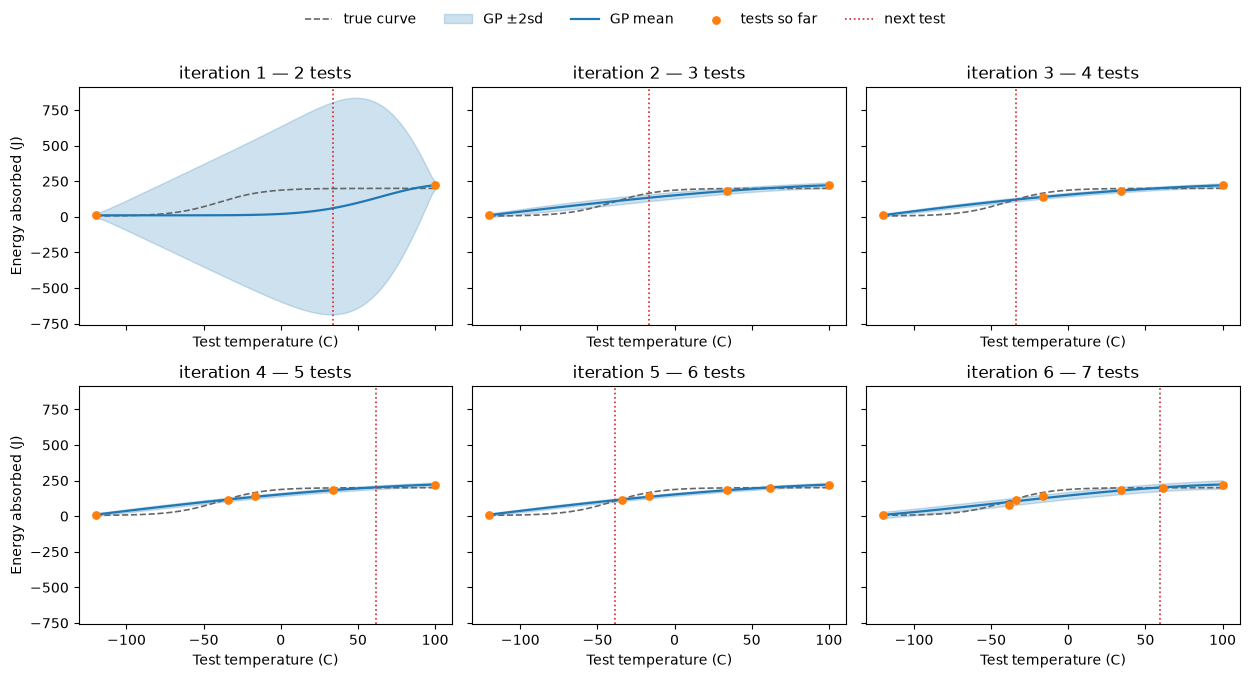

In [17]:
grid = np.linspace(*BOUNDS, 400)
truth = simulator.true_curve(grid)

columns = 3
rows = int(np.ceil(len(history) / columns))
fig, axes = plt.subplots(
    rows, columns, figsize=(4.2 * columns, 3.4 * rows), sharex=True, sharey=True
)
axes = np.atleast_1d(axes).ravel()

for ax, step in zip(axes, history):
    panel = step["curve"]
    t = panel[TEMPERATURE_COL].to_numpy()
    mean, sd = panel["mean"].to_numpy(), panel["sd"].to_numpy()

    ax.plot(grid, truth, color=COLOURS["truth"], lw=1.2, ls="--", label="true curve")
    ax.fill_between(t, mean - 2 * sd, mean + 2 * sd, alpha=0.22,
                    color=COLOURS["gp"], label="GP ±2sd")
    ax.plot(t, mean, color=COLOURS["gp"], lw=1.6, label="GP mean")
    ax.scatter(
        step["observed"][TEMPERATURE_COL], step["observed"][ENERGY_COL],
        s=28, color=COLOURS["tests"], zorder=3, label="tests so far",
    )
    for temperature in step["picked"]:
        ax.axvline(temperature, color=COLOURS["picked"], lw=1.2, ls=":", label="next test")

    # The count goes in the title: a shared legend can only carry one label,
    # so putting it there would show every panel the last panel's count.
    ax.set_title(f"iteration {step['iteration']} — {step['n_tests']} tests")

for ax in axes[len(history):]:
    ax.set_visible(False)
for ax in axes[:len(history)]:
    ax.set_xlabel(TEMPERATURE_COL)
for ax in axes[::columns]:
    ax.set_ylabel(ENERGY_COL)

handles, labels = axes[0].get_legend_handles_labels()
seen = dict(zip(labels, handles))
fig.legend(seen.values(), seen.keys(), loc="upper center", ncol=5, frameon=False)
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

### Where the acquisition chose to test

Every chosen temperature, in order. An uncertainty-reduction acquisition should
cluster these around the transition rather than spreading them evenly — the
shelves are already pinned by the initial design, so there is little left to
learn out there.

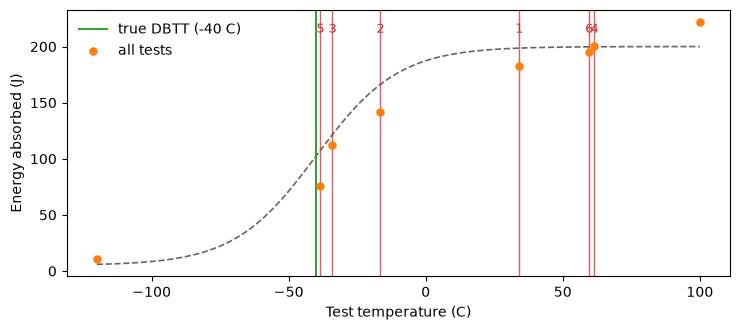

In [18]:
chosen = [(step["iteration"], t) for step in history for t in step["picked"]]

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(grid, truth, color=COLOURS["truth"], lw=1.2, ls="--")
ax.axvline(simulator.dbtt, color=COLOURS["true_dbtt"], lw=1.4, label=f"true DBTT ({simulator.dbtt:g} C)")
for iteration, temperature in chosen:
    ax.axvline(temperature, color=COLOURS["picked"], lw=1.0, alpha=0.75)
    ax.annotate(
        str(iteration), (temperature, ax.get_ylim()[1]),
        ha="center", va="bottom", fontsize=9, color=COLOURS["picked"],
    )
ax.scatter(
    campaign[TEMPERATURE_COL], campaign[ENERGY_COL],
    s=26, color=COLOURS["tests"], zorder=3, label="all tests",
)
ax.set_xlabel(TEMPERATURE_COL)
ax.set_ylabel(ENERGY_COL)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### The posterior as a saved dataset

`Temp to Energy - GP plot` returns a payload that lives only as long as the
job. **Predict slice** runs the same prediction but *saves* the posterior mean
and uncertainty as project datasets, so they persist, can be opened in the GUI,
and can be downloaded and compared later.

Mean and uncertainty are separate resources, because `PredictModel` emits them
as separate handles and no node here joins two datasets. `saved_prediction()`
downloads both and puts them beside the grid, which comes back inline with the
job.

In [19]:
run_saved(client, project_id, saved_ids["Train model"])  # train on the final campaign

posterior_curve = saved_prediction(
    client, project_id,
    run_saved(client, project_id, saved_ids["Predict slice"]),
)
print(f"saved as {MEAN_NAME!r} and {UNCERTAINTY_NAME!r} in the project")
posterior_curve.head()

saved as 'dbtt_gp_mean' and 'dbtt_gp_sd' in the project


,Test temperature (C),mean,sd
0,-120.0,8.863078,10.849282
1,-117.8,11.062192,10.858007
2,-115.6,13.283458,10.882531
3,-113.4,15.526317,10.920471
4,-111.2,17.790199,10.969577


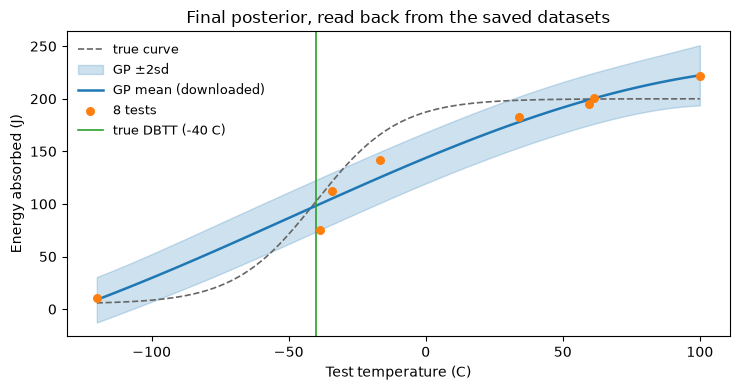

In [20]:
t_curve = posterior_curve[TEMPERATURE_COL].to_numpy()
mean_curve = posterior_curve["mean"].to_numpy()
sd_curve = posterior_curve["sd"].to_numpy()

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(grid, truth, color="0.4", lw=1.2, ls="--", label="true curve")
ax.fill_between(
    t_curve, mean_curve - 2 * sd_curve, mean_curve + 2 * sd_curve,
    alpha=0.22, color="C0", label="GP ±2sd",
)
ax.plot(t_curve, mean_curve, color="C0", lw=1.8, label="GP mean (downloaded)")
ax.scatter(
    campaign[TEMPERATURE_COL], campaign[ENERGY_COL],
    s=30, color="C1", zorder=3, label=f"{len(campaign)} tests",
)
ax.axvline(simulator.dbtt, color="C2", lw=1.2, label=f"true DBTT ({simulator.dbtt:g} C)")
ax.set_xlabel(TEMPERATURE_COL)
ax.set_ylabel(ENERGY_COL)
ax.set_title("Final posterior, read back from the saved datasets")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

### Validation

The validation workflow scores the final model and produces a parity plot. It
is pointed at the campaign itself here, so these are **training** scores — swap
`dataset_id` for a held-out resource to get an honest generalisation estimate.

In [21]:
scores = outputs(run_saved(client, project_id, saved_ids["Validate energy model"]))
as_frame(scores["Score_scores"])

,metric_name,score
0,MSE,118.794937
1,RMSE,10.899309
2,R2,0.974164


---
<a id="section-3"></a>
## 3. The DBTT, with its uncertainty

The GP is a good *interpolator*, but it has no notion of a transition
temperature: reading one off a posterior mean gives a number with no
uncertainty attached. This section answers the question the campaign is
actually for, from the model section 2 produced.

Take the GP posterior that section 2 saved, find where it crosses the
mid-shelf energy $(LS + US)/2$ — the shelves being the extremes the slice
reaches — and propagate the predictive uncertainty through the slope by the
delta method:

$$\mathrm{sd}_\mathrm{DBTT} \;\approx\; \frac{\mathrm{sd}(T^*)}{\left|\mathrm{d}Y/\mathrm{d}T\right|(T^*)}$$

There is no new Engine work here. `posterior_curve` is the slice the
**Predict slice** workflow already saved to the project and we downloaded
above.

> **Read the spread with care.** The numerator is a *predictive* standard
> deviation, so it carries the material's test-to-test scatter. The
> denominator is the transition gradient — which is exactly what active
> learning spends its specimens resolving. A steep gradient makes the interval
> tight, and tight is not the same as right. The notes at the end say what
> this estimator does and does not account for.

In [22]:
#@title Reading the DBTT off a fitted curve { display-mode: "form" }
# Covers
#   dbtt_from_curve()    the DBTT read off a fitted model's posterior curve:
#                        the mid-shelf crossing, with the delta method for the
#                        spread around it.
#   CurveDBTT            what that returns - the crossing, its uncertainty, the
#                        mid-shelf level, and the gradient the delta method
#                        divides by.
#
# The posterior curve itself comes from the Engine (section 2). Everything
# here is arithmetic on that curve, so the cell needs nothing but numpy.


@dataclass
class CurveDBTT:
    """The DBTT read off a fitted model's posterior curve."""

    dbtt: float                 # where the curve crosses the mid-shelf energy [C]
    std: Optional[float]        # first-order uncertainty [C]
    level: float                # the mid-shelf energy it crosses [J]
    gradient: float             # curve slope there [J/C]; the delta method divides by it
    lower_shelf: float
    upper_shelf: float
    n_crossings: int            # >1 means the fit is not monotonic; the steepest was taken

    def __repr__(self) -> str:
        spread = "" if self.std is None else f" +/- {self.std:.2f}"
        return f"CurveDBTT(dbtt={self.dbtt:.2f}{spread})"


def dbtt_from_curve(temperature, mean, sd=None) -> CurveDBTT:
    """Read the DBTT off a fitted model's posterior, with its uncertainty.

    This works on a model's own posterior curve — the mean and standard
    deviation a GP predicts across a temperature slice — rather than on the
    measurements. The DBTT is the crossing of the mid-shelf energy,
    ``(LS + US) / 2``, with the shelves taken as the curve's extremes.

    The uncertainty is propagated to first order through the slope,

        sd_DBTT  ~=  sd(T*) / |dY/dT|(T*)

    which is the delta method. It linearises, so it is only as good as the curve
    being locally straight over ``+/- sd``; on a shallow transition, or where
    the slice is too coarse to resolve the gradient, it will be optimistic. It
    also ignores the correlation between neighbouring temperatures, which a
    draw-based estimate would capture — the Engine exposes no posterior draws,
    so that is not available here.
    """
    t = np.asarray(temperature, dtype=float).reshape(-1)
    y = np.asarray(mean, dtype=float).reshape(-1)
    if t.size != y.size:
        raise ValueError(f"temperature and mean differ in length: {t.size} vs {y.size}")
    if t.size < 3:
        raise ValueError("need at least three points to locate a crossing")

    s = None
    if sd is not None:
        s = np.asarray(sd, dtype=float).reshape(-1)
        # Validate before reordering: indexing a short `sd` with the full
        # ordering raises IndexError rather than saying what is wrong.
        if s.size != t.size:
            raise ValueError(f"sd differs in length: {s.size} vs {t.size}")

    order = np.argsort(t)
    t, y = t[order], y[order]
    if s is not None:
        s = s[order]

    lower_shelf, upper_shelf = float(y.min()), float(y.max())
    level = 0.5 * (lower_shelf + upper_shelf)

    above = y >= level
    crossings = np.flatnonzero(np.diff(above.astype(int)) != 0)
    if crossings.size == 0:
        raise ValueError(
            "the curve never crosses its own mid-shelf energy; it is probably "
            "not a transition over this range"
        )

    # Linear interpolation within each crossing interval, then keep the
    # steepest: that is the transition, and any others are GP wiggle.
    def interpolate(i: int) -> tuple:
        t0, t1, y0, y1 = t[i], t[i + 1], y[i], y[i + 1]
        slope = (y1 - y0) / (t1 - t0)
        return (t0 + (level - y0) / slope if slope != 0 else t0), slope

    candidates = [interpolate(int(i)) for i in crossings]
    dbtt, gradient = max(candidates, key=lambda c: abs(c[1]))

    std = None
    if s is not None:
        sd_at_crossing = float(np.interp(dbtt, t, s))
        std = (float(sd_at_crossing / abs(gradient))
               if gradient != 0 and np.isfinite(gradient) else None)

    return CurveDBTT(
        dbtt=float(dbtt), std=std, level=level, gradient=float(gradient),
        lower_shelf=lower_shelf, upper_shelf=upper_shelf, n_crossings=int(crossings.size),
    )

In [23]:
read = dbtt_from_curve(
    posterior_curve[TEMPERATURE_COL], posterior_curve["mean"], posterior_curve["sd"]
)
print(read)
print(f"  mid-shelf level: {read.level:.1f} J   gradient there: {read.gradient:.3f} J/C")
print(f"  shelves read off the slice: LS = {read.lower_shelf:.1f} J, US = {read.upper_shelf:.1f} J")
print(f"  crossings found: {read.n_crossings}")

CurveDBTT(dbtt=-25.13 +/- 10.64)
  mid-shelf level: 115.6 J   gradient there: 1.150 J/C
  shelves read off the slice: LS = 8.9 J, US = 222.3 J
  crossings found: 1


### How it compares to the truth

The simulator knows the answer, so the estimate can be scored directly — a
luxury no real campaign has. What matters is not whether the point estimate
lands close, but whether the interval is *honest*: a 95% interval that misses
the truth is a worse result than a wider one that contains it.

In [24]:
low, high = read.dbtt - 1.96 * read.std, read.dbtt + 1.96 * read.std
contains = low <= simulator.dbtt <= high

print(f"95% interval [{low:.2f}, {high:.2f}] "
      f"{'contains' if contains else 'does NOT contain'} the true DBTT "
      f"({simulator.dbtt:g} C)")

pd.DataFrame([
    {"quantity": "GP crossing", "DBTT (C)": read.dbtt, "sd (C)": read.std,
     "low": low, "high": high},
    {"quantity": "truth", "DBTT (C)": simulator.dbtt, "sd (C)": np.nan,
     "low": np.nan, "high": np.nan},
]).round(2)

95% interval [-46.00, -4.27] contains the true DBTT (-40 C)


,quantity,DBTT (C),sd (C),low,high
0,GP crossing,-25.13,10.64,-46.0,-4.27
1,truth,-40.00,NaN,NaN,NaN


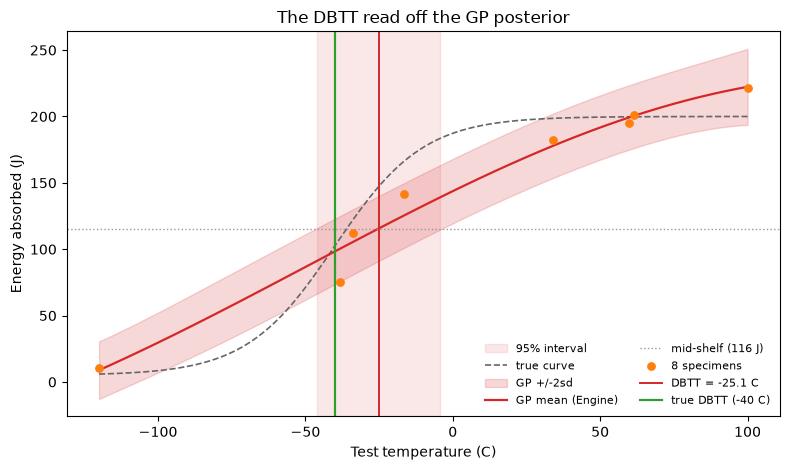

In [25]:
t = campaign[TEMPERATURE_COL].to_numpy()
y = campaign[ENERGY_COL].to_numpy()

fig, ax = plt.subplots(figsize=(8, 4.8))

ax.axvspan(low, high, color=COLOURS["dbtt"], alpha=0.10, label="95% interval")
ax.plot(grid, truth, color=COLOURS["truth"], lw=1.2, ls="--", label="true curve")
ax.fill_between(
    t_curve, mean_curve - 2 * sd_curve, mean_curve + 2 * sd_curve,
    color=COLOURS["posterior"], alpha=0.18, label="GP +/-2sd",
)
ax.plot(t_curve, mean_curve, color=COLOURS["posterior"], lw=1.6, label="GP mean (Engine)")
ax.axhline(read.level, color="0.6", lw=1.0, ls=":",
           label=f"mid-shelf ({read.level:.0f} J)")
ax.scatter(t, y, s=28, color=COLOURS["tests"], zorder=3, label=f"{len(t)} specimens")
ax.axvline(read.dbtt, color=COLOURS["dbtt"], lw=1.4, label=f"DBTT = {read.dbtt:.1f} C")
ax.axvline(simulator.dbtt, color=COLOURS["true_dbtt"], lw=1.6,
           label=f"true DBTT ({simulator.dbtt:g} C)")

ax.set_xlabel(TEMPERATURE_COL)
ax.set_ylabel(ENERGY_COL)
ax.set_title("The DBTT read off the GP posterior")
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

### The estimate against the specimen count

The GP posterior was saved at every iteration, so the same crossing can be read
off each one — no extra Engine work, just arithmetic on curves already in
`history`. The result is the campaign's own learning curve: the estimate, and
the interval around it, against the number of specimens spent on it.

**Do not expect a clean convergence.** Each iteration refits the GP on a
dataset that has changed, and the delta-method spread divides by the *gradient
at the crossing* — which moves with the fit. A specimen that steepens the
transition shrinks the interval sharply; one that flattens it opens the
interval back up again. So the trace wanders, and the final interval is not
reliably the narrowest one the campaign passed through. What more specimens
buy is that the wandering happens in a smaller region, not that every step
improves on the last.

Watch the two panels separately. An estimate that has stopped moving, with a
tight interval around it, is the failure mode this estimator is prone to — and
the trace below shows how far that is from guaranteed at ten specimens.


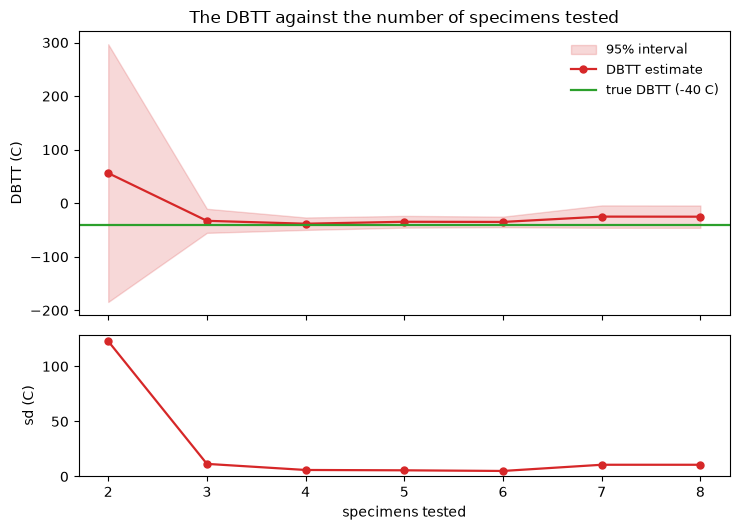

,n_tests,dbtt,sd
0,2,56.25,122.78
1,3,-32.86,11.45
2,4,-38.24,5.92
3,5,-34.63,5.62
4,6,-34.92,5.03
5,7,-25.00,10.65
6,8,-25.13,10.64


In [26]:
track = []
for step in history:
    panel = step["curve"]
    try:
        at = dbtt_from_curve(panel[TEMPERATURE_COL], panel["mean"], panel["sd"])
    except ValueError:
        continue  # an early GP need not cross its own mid-shelf energy at all
    track.append({"n_tests": step["n_tests"], "dbtt": at.dbtt, "sd": at.std})

# `history` records each iteration *before* its pick is tested, so the final
# campaign is only represented by the fit made at the top of section 3.
track.append({"n_tests": len(campaign), "dbtt": read.dbtt, "sd": read.std})
track = pd.DataFrame(track)

fig, (top, bottom) = plt.subplots(
    2, 1, figsize=(7.5, 5.4), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
)

top.fill_between(
    track["n_tests"], track["dbtt"] - 1.96 * track["sd"],
    track["dbtt"] + 1.96 * track["sd"],
    color=COLOURS["dbtt"], alpha=0.18, label="95% interval",
)
top.plot(track["n_tests"], track["dbtt"], "o-", color=COLOURS["dbtt"],
         lw=1.6, ms=5, label="DBTT estimate")
top.axhline(simulator.dbtt, color=COLOURS["true_dbtt"], lw=1.6,
            label=f"true DBTT ({simulator.dbtt:g} C)")
top.set_ylabel("DBTT (C)")
top.legend(frameon=False, fontsize=9)
top.set_title("The DBTT against the number of specimens tested")

bottom.plot(track["n_tests"], track["sd"], "o-", color=COLOURS["dbtt"], lw=1.6, ms=5)
bottom.set_xlabel("specimens tested")
bottom.set_ylabel("sd (C)")
bottom.set_ylim(bottom=0)

fig.tight_layout()
plt.show()

track.round(2)

---
## Notes

- **The interval is the deliverable, not the point estimate.** A campaign of
  this size pins the DBTT down to a few degrees; quoting a single number hides
  that.
- **The delta method is optimistic where the gradient is steep.** It divides a
  *predictive* standard deviation — measurement scatter included — by the
  transition gradient, and active learning spends its budget resolving exactly
  that gradient. The result is a tight interval, which is not the same as a
  correct one. It also linearises at the crossing, so it is only as good as
  the curve being locally straight over ±sd, and it ignores the correlation
  between neighbouring temperatures, which a draw-based estimate would
  capture. The Engine exposes no posterior draws: `PredictModel`'s `samples`
  handle is a single forward-pass bundle, not an ensemble.
- **The GP has no notion of a transition.** The crossing is read off a curve
  fitted for interpolation, so the shelves are whatever extremes the slice
  happens to reach. A slice that stops short of either shelf moves the
  mid-shelf level, and the answer with it — keep `BOUNDS` wide enough that the
  curve is flat at both ends.
- **A model-free route exists and is not in this notebook.** Fitting the AHT
  form to the measurements directly makes the problem linear in the shelves,
  so they and the noise precision integrate out in closed form, and sweeping
  the evidence over a `(DBTT, C)` grid gives `p(DBTT | data)` itself — an
  asymmetric density rather than a ± number. It is a different estimator of
  the same quantity, with a spread that is not comparable like-for-like to
  this one. It was removed when this section was cut back to the GP route and
  is recoverable from git history.
- **Two things about reading Engine results.** Only some node outputs come
  back as *values* — `UncertaintyPlot` returns the posterior inline, while
  `PredictModel`'s and `Recommend`'s own handles return S3 references. And
  creating a resource is a different call from versioning one: `upload`
  refuses a name the project already holds, `update` adds a version and keeps
  the id. The saved workflows point at that id, which is why the loop never
  has to edit a graph.
- **The band plateaus, it does not vanish.** It is the predictive standard
  deviation, so it bottoms out at the material's test-to-test scatter however
  many specimens are added.